In [2]:
import polars as pl
import seaborn as sns

In [48]:
oneper_df = pl.read_csv("/home/shenrunx/igvf/varchamp/2025_laval_submitted/3_integrated_assay_results/1_inputs/imaging_analyses_summary.tsv", separator="\t")
cava_df = pl.read_csv("/home/shenrunx/igvf/varchamp/2025_Pillar_VarChAMP/2_individual_assay_analyses/imaging/3_outputs/1_snakemake_pipeline/3.smp_results_analyses/3.classification_analyses/2025_01_Batch_13-14/altered_GFP_summary_auroc.csv")

In [49]:
total_df = pl.concat([
    oneper_df.select(pl.col(["gene_allele","Altered_95th_perc_GFP","Altered_99th_perc_GFP","AUROC_Mean_GFP"])).rename({
        "AUROC_Mean_GFP": "AUROC_Mean"
    }),
    cava_df.rename({
        "allele_0": "gene_allele",
        "Altered_GFP_95_both_batches": "Altered_95th_perc_GFP",
        "Altered_GFP_99_both_batches": "Altered_99th_perc_GFP"
    }).select(pl.col(["gene_allele","Altered_95th_perc_GFP","Altered_99th_perc_GFP","AUROC_Mean"])).with_columns(
        pl.col("Altered_95th_perc_GFP").cast(pl.Float64),
        pl.col("Altered_99th_perc_GFP").cast(pl.Float64),
    )
])
total_df

gene_allele,Altered_95th_perc_GFP,Altered_99th_perc_GFP,AUROC_Mean
str,f64,f64,f64
"""GRN_Thr182Met""",0.0,0.0,0.689456
"""SMAD3_Thr261Ile""",0.0,0.0,0.904596
"""GRN_Cys105Arg""",0.0,0.0,0.859037
"""SMAD3_Arg287Trp""",0.0,0.0,0.842628
"""AGXT_Phe152Ile""",0.0,0.0,0.711672
…,…,…,…
"""CCM2_Glu223Val""",0.0,0.0,0.890079
"""G6PD_Ile48Thr""",0.0,0.0,0.896083
"""BRCA1_Gly602Ala""",0.0,0.0,0.9335


In [50]:
total_df.with_columns(
    pl.col("gene_allele").str.split("_").list.get(0).alias("gene")
).unique("gene")

gene_allele,Altered_95th_perc_GFP,Altered_99th_perc_GFP,AUROC_Mean,gene
str,f64,f64,f64,str
"""GATA2_Pro41Ala""",0.0,0.0,0.600477,"""GATA2"""
"""PLP1_Thr121Ile""",null,null,null,"""PLP1"""
"""SMN2_Gly287Arg""",1.0,0.0,0.97811,"""SMN2"""
"""KCTD1_Ala30Glu""",0.0,0.0,0.781115,"""KCTD1"""
"""WRAP53_Arg68Gly""",0.0,0.0,0.669654,"""WRAP53"""
…,…,…,…,…
"""IRAK4_Ala428Thr""",0.0,0.0,0.638454,"""IRAK4"""
"""ZMYND10_Arg243Cys""",0.0,0.0,null,"""ZMYND10"""
"""PHYH_Arg275Trp""",0.0,0.0,0.872204,"""PHYH"""


In [29]:
oneper_df.select(["Altered_95th_perc_GFP", "Altered_99th_perc_GFP"]).sum() / oneper_df.shape[0]

Altered_95th_perc_GFP,Altered_99th_perc_GFP
f64,f64
0.296689,0.149669


In [30]:
cava_df.rename({
        "allele_0": "gene_allele",
        "Altered_GFP_95_both_batches": "Altered_95th_perc_GFP",
        "Altered_GFP_99_both_batches": "Altered_99th_perc_GFP"
    }).select(pl.col(["gene_allele","Altered_95th_perc_GFP","Altered_99th_perc_GFP","AUROC_Mean"])).with_columns(
        pl.col("Altered_95th_perc_GFP").cast(pl.Float64),
        pl.col("Altered_99th_perc_GFP").cast(pl.Float64),
    ).select(["Altered_95th_perc_GFP", "Altered_99th_perc_GFP"]).sum() / oneper_df.shape[0]

Altered_95th_perc_GFP,Altered_99th_perc_GFP
f64,f64
0.051656,0.01457


In [13]:
total_df.select(["Altered_95th_perc_GFP", "Altered_99th_perc_GFP"]).sum() / total_df.shape[0]

Altered_95th_perc_GFP,Altered_99th_perc_GFP
f64,f64
0.219167,0.103333


In [26]:
total_df.select(["Altered_95th_perc_GFP", "Altered_99th_perc_GFP"]).sum()

Altered_95th_perc_GFP,Altered_99th_perc_GFP
f64,f64
263.0,124.0


In [25]:
total_df.shape[0]

1200

In [3]:
clin_var_annot_df = pl.read_csv("/home/shenrunx/igvf/varchamp/2025_laval_submitted/4_compare_AI_scores/3_outputs/varchamp_consolidated_alleles_clinvar_gnomad_dbnsfp_scores.tsv", separator="\t", infer_schema_length=10000)
clin_var_annot_df = clin_var_annot_df.with_columns(
    pl.concat_str([pl.col("symbol"), pl.col("aa_change")], separator="_").alias("gene_allele")
)

In [4]:
clin_var_annot_df


orf_id,symbol,nt_change,aa_change,ensembl_gene_id,chr,chr_pos_38,spdi,ccsb_allele_id,ccsb_mutation_id,mutation_id_rc4,mutation_id_cegs2,mutation_id_edgotyping3,entry_plate,entry_well,collection,sequence,#AlleleID,Type,Name,GeneID,GeneSymbol,HGNC_ID,ClinicalSignificance,ClinSigSimple,LastEvaluated,RS# (dbSNP),nsv/esv (dbVar),RCVaccession,PhenotypeIDS,PhenotypeList,Origin,OriginSimple,Assembly,ChromosomeAccession,Chromosome,Start,…,nsv/esv (dbVar)_dbnsfp,RCVaccession_dbnsfp,PhenotypeIDS_dbnsfp,PhenotypeList_dbnsfp,Origin_dbnsfp,OriginSimple_dbnsfp,Assembly_dbnsfp,ChromosomeAccession_dbnsfp,Chromosome_dbnsfp,Start_dbnsfp,Stop_dbnsfp,Cytogenetic_dbnsfp,ReviewStatus_dbnsfp,NumberSubmitters_dbnsfp,Guidelines_dbnsfp,TestedInGTR_dbnsfp,OtherIDs_dbnsfp,SubmitterCategories_dbnsfp,VariationID_dbnsfp,PositionVCF_dbnsfp,ReferenceAlleleVCF_dbnsfp,AlternateAlleleVCF_dbnsfp,SomaticClinicalImpact_dbnsfp,SomaticClinicalImpactLastEvaluated_dbnsfp,ReviewStatusClinicalImpact_dbnsfp,Oncogenicity_dbnsfp,OncogenicityLastEvaluated_dbnsfp,ReviewStatusOncogenicity_dbnsfp,SCVsForAggregateGermlineClassification_dbnsfp,SCVsForAggregateSomaticClinicalImpact_dbnsfp,SCVsForAggregateOncogenicityClassification_dbnsfp,clinvar_nt_change_dbnsfp,clinvar_aa_change_dbnsfp,RefSeq_mRNA_dbnsfp,StarStatus_dbnsfp,clinvar_clnsig_clean_dbnsfp,gene_allele
i64,str,str,str,str,str,i64,str,str,str,str,str,str,str,str,str,str,f64,str,str,f64,str,str,str,f64,str,f64,str,str,str,str,str,str,str,str,str,f64,…,str,str,str,str,str,str,str,str,str,i64,i64,str,str,i64,str,str,str,i64,i64,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i64,str,str
71569,"""OTC""","""240G>T""","""Lys80Asn""","""ENSG00000036473""","""X""",38369819,"""NC_000023.11:38369819:G:T""","""ALE00005236""","""CCSBVarC005236""","""NULL""","""205820""","""NULL""","""GDEhDisVCh_40048""","""B07""","""CEGS2""","""ATGCTGTTTAATCTGAGGATCCTGTTAAAC…",103032.0,"""single nucleotide variant""","""NM_000531.6(OTC):c.240G>T (p.L…",5009.0,"""OTC""","""HGNC:8512""","""Pathogenic""",1.0,"""-""",7.2554333e7,"""-""","""RCV000083371""","""MedGen:CN517202""","""not provided""","""unknown""","""unknown""","""GRCh38""","""NC_000023.11""","""X""",3.8369819e7,…,"""-""","""RCV000083371""","""MedGen:CN517202""","""not provided""","""unknown""","""unknown""","""GRCh38""","""NC_000023.11""","""X""",38369819,38369819,"""Xp11.4""","""no assertion criteria provided""",1,"""ACMG2016,ACMG2021,ACMG2022""","""N""","""ClinGen:CA224512""",2,97140,38369819,"""G""","""T""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV000115457""","""-""","""-""","""240G>T ""","""Lys80Asn""","""NM_000531.6""",null,"""1_Pathogenic""","""OTC_Lys80Asn"""
575,"""AGA""","""770C>T""","""Thr257Ile""","""ENSG00000038002""","""4""",177434418,"""NC_000004.12:177434418:G:A""","""ALE00005310""","""CCSBVarC005310""","""NULL""","""213789""","""NULL""","""GDEhDisVCh_40063""","""A09""","""CEGS2""","""ATGGCGCGGAAGTCGAACTTGCCTGTGCTT…",70592.0,"""single nucleotide variant""","""NM_000027.4(AGA):c.770C>T (p.T…",175.0,"""AGA""","""HGNC:318""","""Conflicting classifications of…",1.0,"""Aug 21, 2023""",3.86833434e8,"""-""","""RCV000049362""","""Human Phenotype Ontology:HP:00…","""Aspartylglucosaminuria""","""germline;unknown""","""germline""","""GRCh38""","""NC_000004.12""","""4""",1.77434418e8,…,"""-""","""RCV000049362""","""Human Phenotype Ontology:HP:00…","""Aspartylglucosaminuria""","""germline;unknown""","""germline""","""GRCh38""","""NC_000004.12""","""4""",177434418,177434418,"""4q34.3""","""criteria provided, conflicting…",3,"""-""","""N""","""ClinGen:CA144033,UniProtKB:P20…",2,55953,177434418,"""G""","""A""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV003525620|SCV004217649""","""-""","""-""","""770C>T ""","""Thr257Ile""","""NM_000027.4""",1,"""3_Conflicting""","""AGA_Thr257Ile"""
3743,"""LAMP2""","""928G>A""","""Val310Ile""","""ENSG00000005893""","""X""",120442599,"""NC_000023.11:120442599:C:T""","""ALE00000542""","""CCSBVarC000542""","""6896""","""NULL""

In [8]:
list(clin_var_annot_df.unique(subset="clinvar_clnsig_clean_dbnsfp").sort("clinvar_clnsig_clean_dbnsfp")["clinvar_clnsig_clean_dbnsfp"])

[None, '1_Pathogenic', '2_Benign', '3_Conflicting', '4_VUS', '5_Others']

In [15]:
clinvar_palette_set2 = sns.color_palette("Set2")
clinvar_palette_set2

[(0.4, 0.7607843137254902, 0.6470588235294118),
 (0.9882352941176471, 0.5529411764705883, 0.3843137254901961),
 (0.5529411764705883, 0.6274509803921569, 0.796078431372549),
 (0.9058823529411765, 0.5411764705882353, 0.7647058823529411),
 (0.6509803921568628, 0.8470588235294118, 0.32941176470588235),
 (1.0, 0.8509803921568627, 0.1843137254901961),
 (0.8980392156862745, 0.7686274509803922, 0.5803921568627451),
 (0.7019607843137254, 0.7019607843137254, 0.7019607843137254)]

In [18]:
clinvar_palette_set2 = sns.color_palette("Set2")
clinvar_palette_set2[0], clinvar_palette_set2[1], clinvar_palette_set2[2], clinvar_palette_set2[3], clinvar_palette_set2[4], clinvar_palette_set2[5], clinvar_palette_set2[7] = \
clinvar_palette_set2[1], clinvar_palette_set2[4], clinvar_palette_set2[3], clinvar_palette_set2[2], clinvar_palette_set2[0], clinvar_palette_set2[7], clinvar_palette_set2[5]
clinvar_palette_set2

[(0.9882352941176471, 0.5529411764705883, 0.3843137254901961),
 (0.6509803921568628, 0.8470588235294118, 0.32941176470588235),
 (0.9058823529411765, 0.5411764705882353, 0.7647058823529411),
 (0.5529411764705883, 0.6274509803921569, 0.796078431372549),
 (0.4, 0.7607843137254902, 0.6470588235294118),
 (0.7019607843137254, 0.7019607843137254, 0.7019607843137254),
 (0.8980392156862745, 0.7686274509803922, 0.5803921568627451),
 (1.0, 0.8509803921568627, 0.1843137254901961)]

In [46]:
clinvar_palette[1], clinvar_palette[0], clinvar_palette[2], clinvar_palette[3] = clinvar_palette[0], clinvar_palette[1], clinvar_palette[3], clinvar_palette[2]

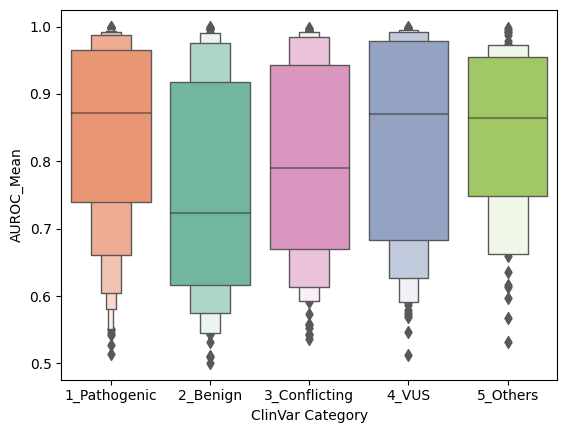

In [47]:
import matplotlib.pyplot as plt
ax = sns.boxenplot(
    data=clin_var_annot_df.join(total_df, on="gene_allele").sort(by="clinvar_clnsig_clean_dbnsfp").to_pandas(),
    palette=clinvar_palette, #saturation=.15,
    x="clinvar_clnsig_clean_dbnsfp", y="AUROC_Mean")
ax.set_xlabel("ClinVar Category")
plt.show()

plt.savefig()